# Guwahati Unified Dataset: Parameter Distributions - VERSION 2


This notebook visualizes important parameters in the unified Guwahati dataset. The CSV is read in chunks and each parameter is sampled independently, so the complete dataset does not need to be loaded into memory.

Semantic fills (for example cloud-base, vertical-visibility, octa, and rain fills) and retained missing values affect the distributions and should be considered when interpreting the plots.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
    
DATA_FILE = Path("..") / "08_unified_dataset" / "guwahati_unified_lstm_dataset_v2_short_cloud_fill_20240811_20260131.csv"
MAX_PLOT_VALUES = 200_000
CHUNK_SIZE = 100_000
    
NUMERIC_PARAMETERS = [
    "CLOUD_Cloud_Base_1", "CLOUD_Cloud_Base_2", "CLOUD_Cloud_Base_3",
    "CLOUD_OCTA1", "CLOUD_OCTA2", "CLOUD_OCTA3", "CLOUD_OCTA4",
    "CLOUD_Vertical_Visibility", "PTU_Pressure_QNH", "PTU_Temperature",
    "PTU_DewPoint", "PTU_Humidity", "PW_Rain_Intensity", "PW_Rain_Sum",
    "VIS_Visibility_MOR", "VIS_RVR", "WIND_Wind_Dir", "WIND_Wind_Speed",
    "WIND_Wind_Gust",
]
SENSOR_FLAGS = [
    "CLOUD_SENSOR_ON", "PTU_SENSOR_ON", "PW_SENSOR_ON",
    "VIS_SENSOR_ON", "WIND_SENSOR_ON",
]
    
def load_numeric_sample(column, max_values=MAX_PLOT_VALUES):
    """Read one column in chunks and return a bounded numeric sample."""
    if not DATA_FILE.exists():
        raise FileNotFoundError(f"Dataset not found: {DATA_FILE.resolve()}")
    sample_parts = []
    total = 0
    try:
        chunks = pd.read_csv(DATA_FILE, usecols=[column], chunksize=CHUNK_SIZE)
    except (ValueError, FileNotFoundError):
        return None
    for chunk in chunks:
        values = pd.to_numeric(chunk[column], errors="coerce").dropna()
        if values.empty:
            continue
        remaining = max_values - total
        if remaining <= 0:
            break
        if len(values) > remaining:
            values = values.sample(remaining, random_state=42)
        sample_parts.append(values)
        total += len(values)
    return pd.concat(sample_parts, ignore_index=True) if sample_parts else None
    
def plot_distribution(column):
    values = load_numeric_sample(column)
    if values is None or values.empty:
        print(f"No numeric data available for {column}.")
        return

    figure, axis = plt.subplots(figsize=(8, 4))
    sns.histplot(values, bins=60, kde=True, ax=axis, color="#1f77b4")
    axis.set_title(f"{column}: histogram and KDE")
    axis.set_xlabel(column)
    axis.set_ylabel("Count")

    figure.tight_layout()
    plt.show()
    print(values.describe())
    
print(f"Dataset: {DATA_FILE.resolve()}")
print(f"Exists: {DATA_FILE.exists()}")

Dataset: D:\IMD\Guwahati\08_unified_dataset\guwahati_unified_lstm_dataset_v2_short_cloud_fill_20240811_20260131.csv
Exists: True


## Dataset overview

In [2]:
header = pd.read_csv(DATA_FILE, nrows=0)
print(f"Columns: {len(header.columns)}")
print("Available columns:")
display(pd.DataFrame({"column": header.columns}))
print("File size (MB):", round(DATA_FILE.stat().st_size / 1024**2, 2))

Columns: 32
Available columns:


,column
0,Datetime
1,CLOUD_Cloud_Base_1
2,CLOUD_Cloud_Base_2
3,CLOUD_Cloud_Base_3
4,CLOUD_SITE
5,CLOUD_OCTA1
6,CLOUD_OCTA2
7,CLOUD_OCTA3
8,CLOUD_OCTA4
9,CLOUD_Vertical_Visibility


File size (MB): 366.54


## Individual parameter distributions

Run each cell independently to inspect one parameter.

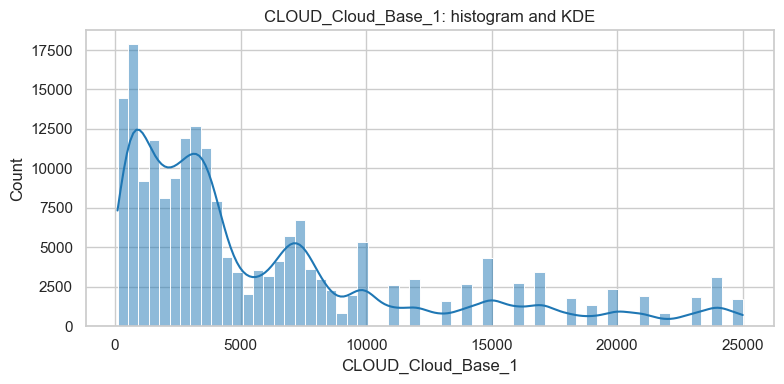

count    200000.000000
mean       5993.844500
std        6076.128509
min         100.000000
25%        1600.000000
50%        3600.000000
75%        7800.000000
max       25000.000000
Name: CLOUD_Cloud_Base_1, dtype: float64


In [3]:
plot_distribution("CLOUD_Cloud_Base_1")

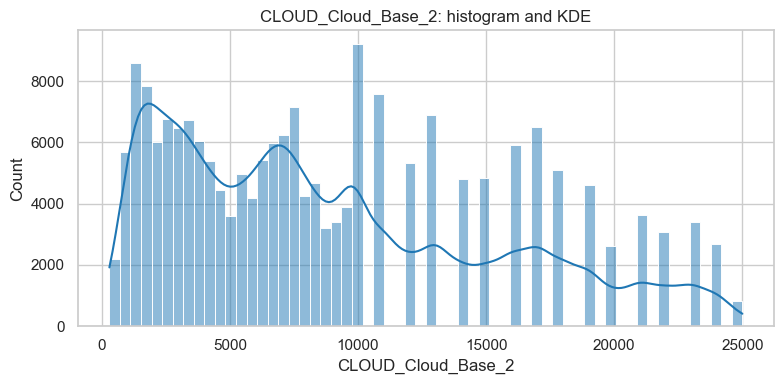

count    200000.000000
mean       8960.934500
std        6329.993916
min         300.000000
25%        3500.000000
50%        7500.000000
75%       13000.000000
max       25000.000000
Name: CLOUD_Cloud_Base_2, dtype: float64


In [4]:
plot_distribution("CLOUD_Cloud_Base_2")

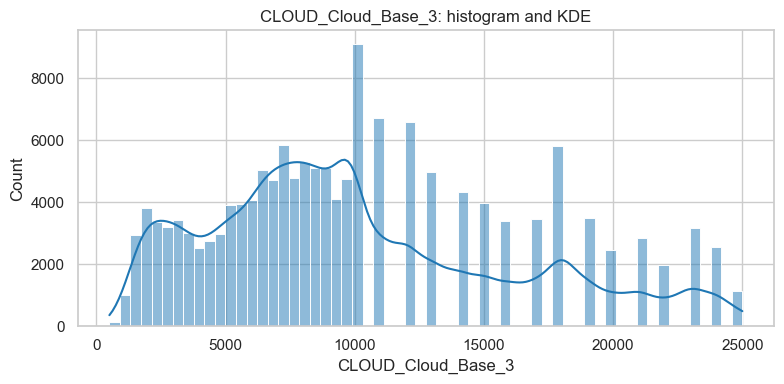

count    151777.000000
mean      10147.304928
std        5891.872554
min         500.000000
25%        6000.000000
50%        9000.000000
75%       14000.000000
max       25000.000000
Name: CLOUD_Cloud_Base_3, dtype: float64


In [5]:
plot_distribution("CLOUD_Cloud_Base_3")

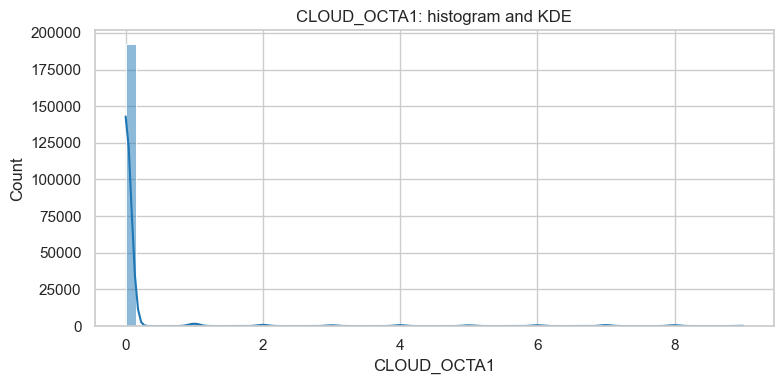

count    200000.000000
mean          0.155190
std           0.923569
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           9.000000
Name: CLOUD_OCTA1, dtype: float64


In [6]:
plot_distribution("CLOUD_OCTA1")

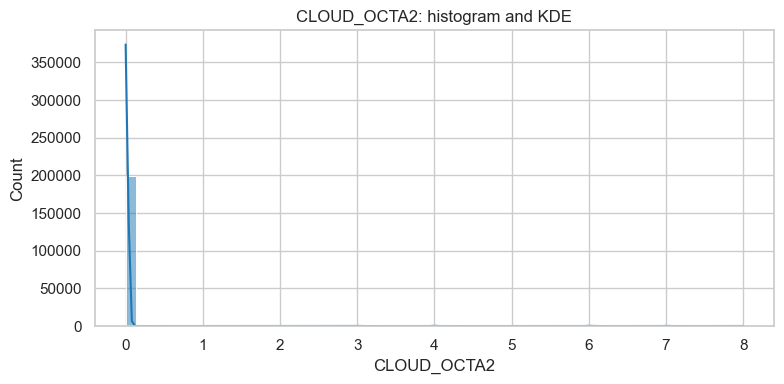

count    200000.00000
mean          0.01812
std           0.32581
min           0.00000
25%           0.00000
50%           0.00000
75%           0.00000
max           8.00000
Name: CLOUD_OCTA2, dtype: float64


In [7]:
plot_distribution("CLOUD_OCTA2")

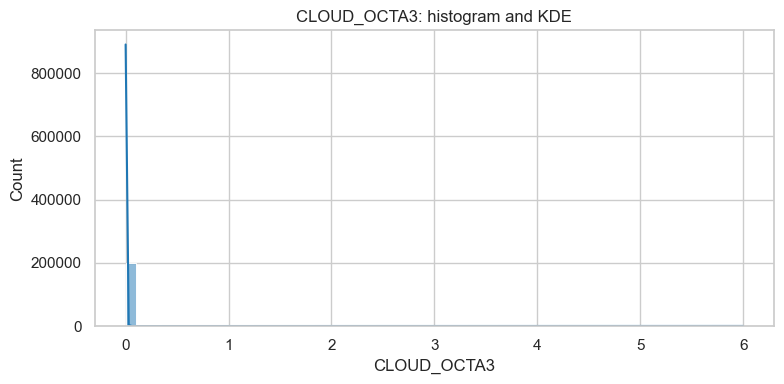

count    200000.000000
mean          0.001780
std           0.102844
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           6.000000
Name: CLOUD_OCTA3, dtype: float64


In [8]:
plot_distribution("CLOUD_OCTA3")

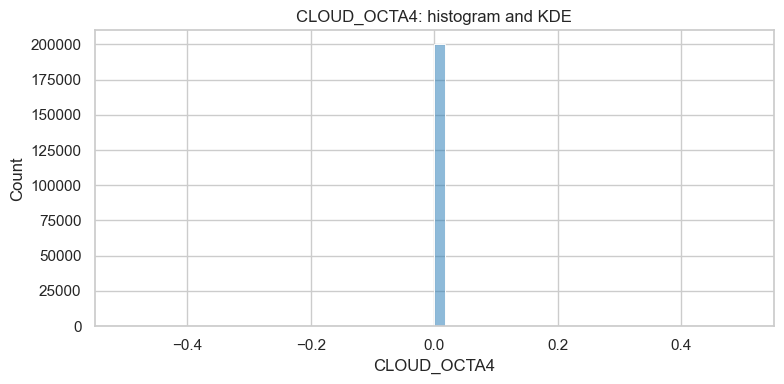

count    200000.0
mean          0.0
std           0.0
min           0.0
25%           0.0
50%           0.0
75%           0.0
max           0.0
Name: CLOUD_OCTA4, dtype: float64


In [9]:
plot_distribution("CLOUD_OCTA4")

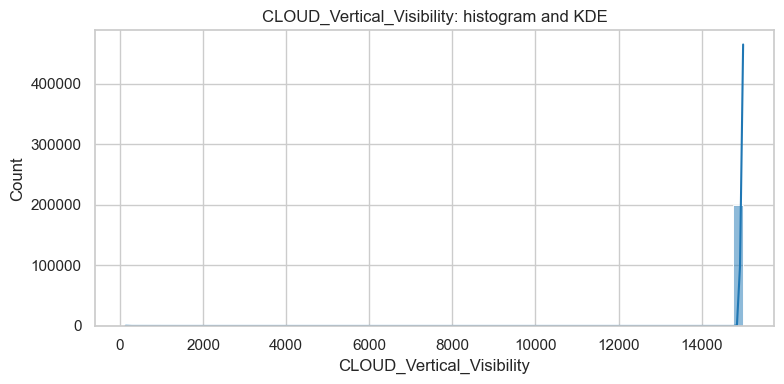

count    200000.000000
mean      14983.649045
std         488.421366
min         133.000000
25%       15000.000000
50%       15000.000000
75%       15000.000000
max       15000.000000
Name: CLOUD_Vertical_Visibility, dtype: float64


In [10]:
plot_distribution("CLOUD_Vertical_Visibility")

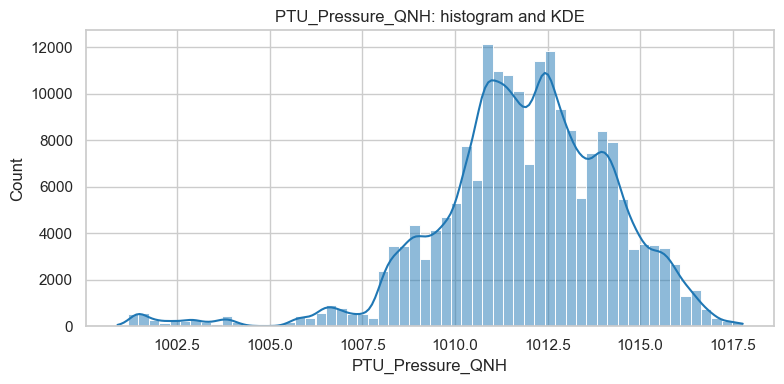

count    200000.000000
mean       1011.874089
std           2.423488
min        1000.890000
25%        1010.640000
50%        1012.040000
75%        1013.520000
max        1017.770000
Name: PTU_Pressure_QNH, dtype: float64


In [11]:
plot_distribution("PTU_Pressure_QNH")

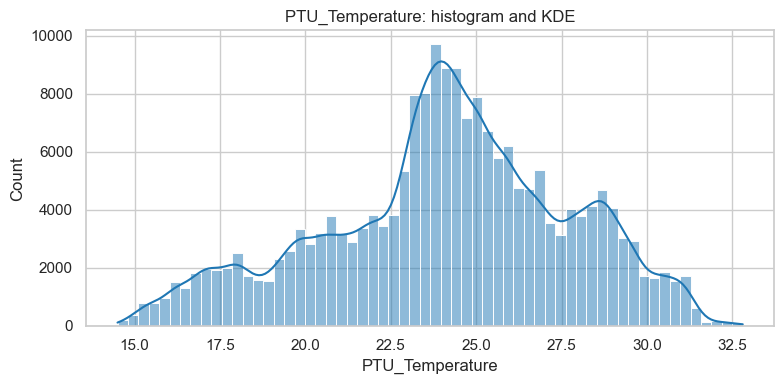

count    200000.000000
mean         24.099080
std           3.618042
min          14.500000
25%          21.920000
50%          24.300000
75%          26.580000
max          32.800000
Name: PTU_Temperature, dtype: float64


In [12]:
plot_distribution("PTU_Temperature")

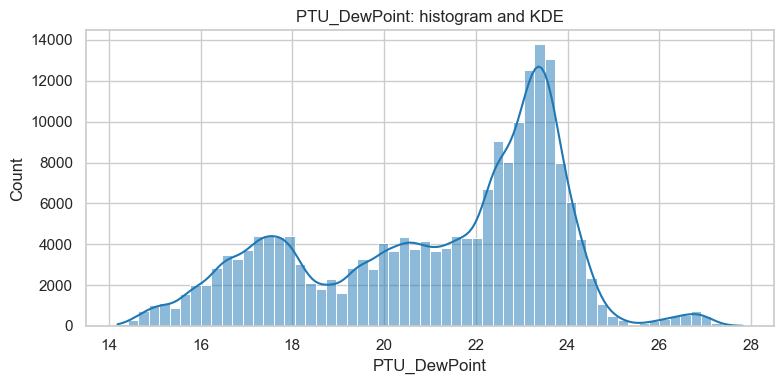

count    200000.000000
mean         21.142337
std           2.723580
min          14.190000
25%          18.970000
50%          22.080000
75%          23.320000
max          27.820000
Name: PTU_DewPoint, dtype: float64


In [13]:
plot_distribution("PTU_DewPoint")

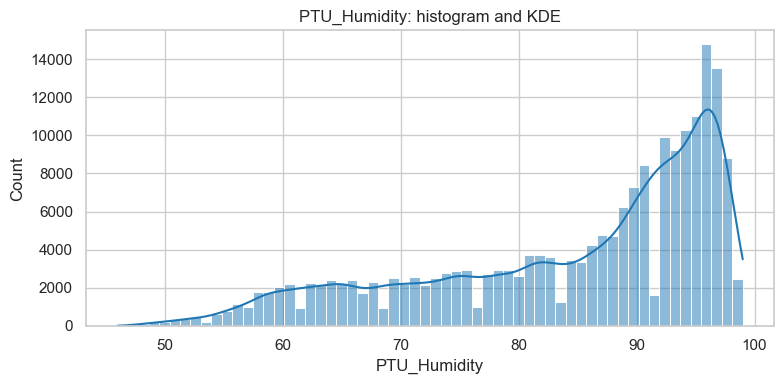

count    200000.000000
mean         84.393155
std          12.385414
min          46.000000
25%          76.000000
50%          89.000000
75%          95.000000
max          99.000000
Name: PTU_Humidity, dtype: float64


In [14]:
plot_distribution("PTU_Humidity")

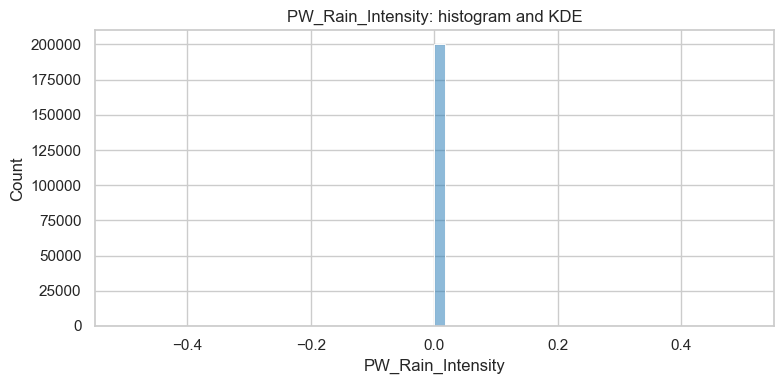

count    200000.0
mean          0.0
std           0.0
min           0.0
25%           0.0
50%           0.0
75%           0.0
max           0.0
Name: PW_Rain_Intensity, dtype: float64


In [15]:
plot_distribution("PW_Rain_Intensity")

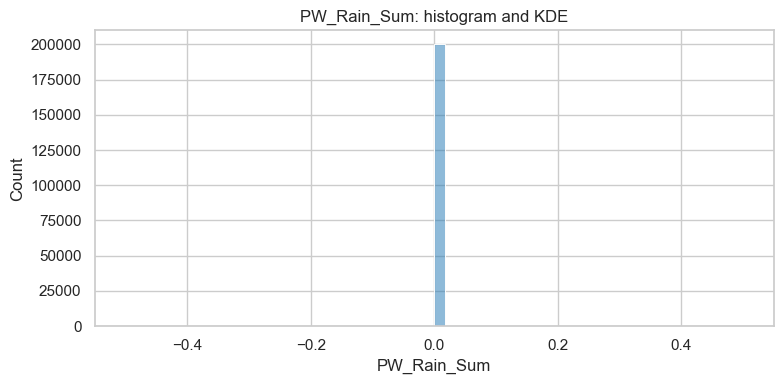

count    200000.0
mean          0.0
std           0.0
min           0.0
25%           0.0
50%           0.0
75%           0.0
max           0.0
Name: PW_Rain_Sum, dtype: float64


In [16]:
plot_distribution("PW_Rain_Sum")

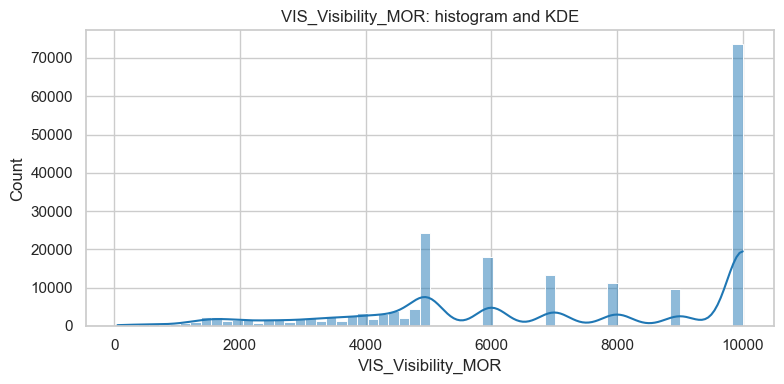

count    200000.000000
mean       6955.050000
std        2868.990942
min          50.000000
25%        4800.000000
50%        7000.000000
75%       10000.000000
max       10000.000000
Name: VIS_Visibility_MOR, dtype: float64


In [17]:
plot_distribution("VIS_Visibility_MOR")

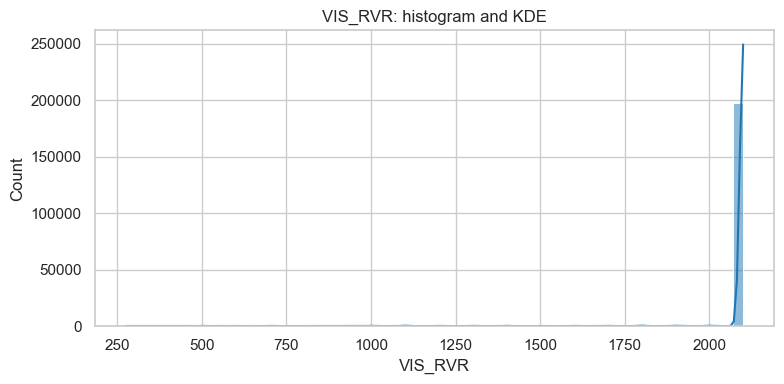

count    200000.000000
mean       2089.781875
std         110.463361
min         275.000000
25%        2100.000000
50%        2100.000000
75%        2100.000000
max        2100.000000
Name: VIS_RVR, dtype: float64


In [18]:
plot_distribution("VIS_RVR")

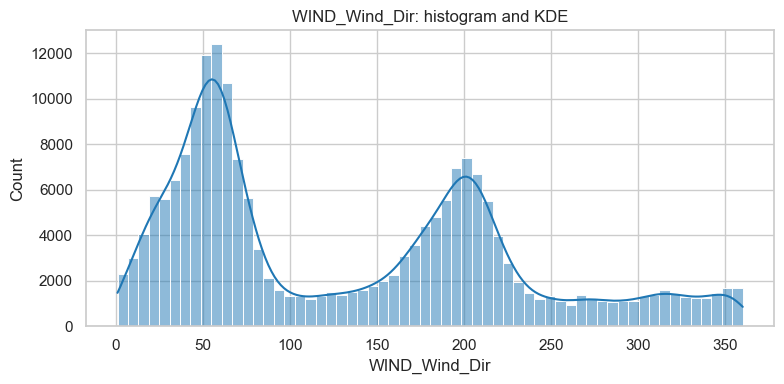

count    200000.000000
mean        132.305530
std          94.784102
min           1.000000
25%          52.000000
50%          99.000000
75%         203.000000
max         360.000000
Name: WIND_Wind_Dir, dtype: float64


In [19]:
plot_distribution("WIND_Wind_Dir")

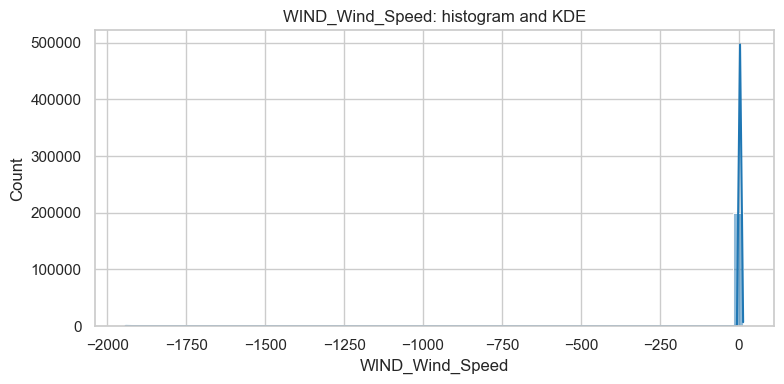

count    200000.000000
mean          2.429934
std          17.644663
min       -1941.900000
25%           0.000000
50%           1.230000
75%           4.870000
max          13.610000
Name: WIND_Wind_Speed, dtype: float64


In [20]:
plot_distribution("WIND_Wind_Speed")

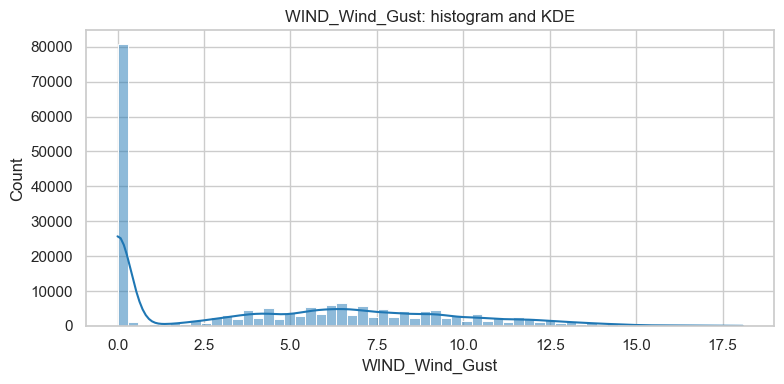

count    200000.000000
mean          4.363044
std           4.337756
min           0.000000
25%           0.000000
50%           4.080000
75%           7.780000
max          18.080000
Name: WIND_Wind_Gust, dtype: float64


In [21]:
plot_distribution("WIND_Wind_Gust")

## Sensor availability flags

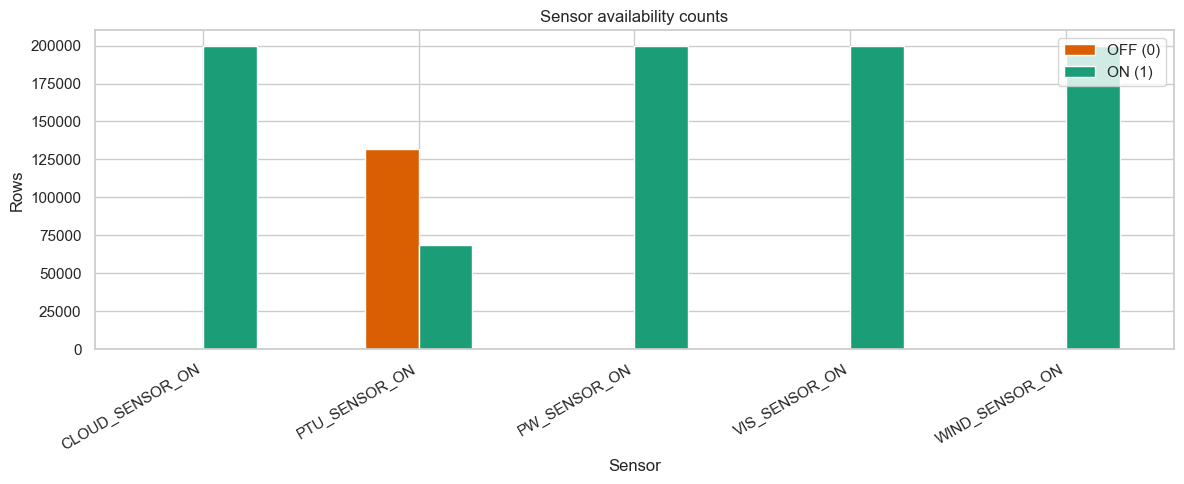

,OFF,ON
CLOUD_SENSOR_ON,8,199992
PTU_SENSOR_ON,131620,68380
PW_SENSOR_ON,14,199986
VIS_SENSOR_ON,2,199998
WIND_SENSOR_ON,2,199998


In [22]:
available_flags = []
for column in SENSOR_FLAGS:
    values = load_numeric_sample(column)
    if values is not None and not values.empty:
        values = values.value_counts().reindex([0, 1], fill_value=0)
        available_flags.append(values.rename(column))
if not available_flags:
    print("No sensor availability flag columns were found.")
else:
    flag_counts = pd.concat(available_flags, axis=1).fillna(0)
    flag_counts.T.plot(kind="bar", figsize=(12, 5), color=["#d95f02", "#1b9e77"])
    plt.title("Sensor availability counts")
    plt.xlabel("Sensor")
    plt.ylabel("Rows")
    plt.xticks(rotation=30, ha="right")
    plt.legend(["OFF (0)", "ON (1)"])
    plt.tight_layout()
    plt.show()
    display(flag_counts.T.rename(columns={0: "OFF", 1: "ON"}))